In [1]:
import os
import SimpleITK as sitk
import cv2
import matplotlib.pyplot as plt
import numpy as np
from scipy.ndimage import binary_opening, gaussian_filter
from skimage.morphology import remove_small_objects
from scipy.ndimage import binary_dilation, binary_fill_holes

file_name = os.listdir(r"Dataset\DICOMs")[0]
dicom_folder_dir = r"Dataset\DICOMs\\" + file_name
nifit_file_dir = r"Dataset\NIFTIs\\" + file_name + ".nii" + '.gz'
file_name

'001'

In [2]:
dicom_folder_dir, os.listdir(dicom_folder_dir)[:5]

('Dataset\\DICOMs\\\\001',
 ['Image (0001).dcm',
  'Image (0002).dcm',
  'Image (0003).dcm',
  'Image (0004).dcm',
  'Image (0005).dcm'])

In [3]:
# convert entire dicom series to nifti including metadata and compress it
def convert_to_nifti(dicom_dir, nifti_dir):
    reader = sitk.ImageSeriesReader()
    dicom_names = reader.GetGDCMSeriesFileNames(dicom_dir)
    reader.SetFileNames(dicom_names)
    image = reader.Execute()
    sitk.WriteImage(image, nifti_dir)

# convert_to_nifti(dicom_folder_dir, nifit_file_dir)

In [4]:
_sitk_image = sitk.ReadImage(nifit_file_dir)
_sitk_image.GetSize(), _sitk_image.GetSpacing()

((512, 512, 1792), (0.8554689884185791, 0.8554689884185791, 0.625))

In [5]:
def show_slice(img, mask, seed):
    fig, ax = plt.subplots(3, 1, figsize=(30, 20))
    mask = mask.astype(np.uint8) if mask is not None else None
    
    ax[0].imshow(img[seed[0], :, :], cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[0].imshow(mask[seed[0], :, :], cmap='Greens', vmin=0, vmax=1, alpha=mask[seed[0], :, :]*0.5)
    ax[0].scatter(seed[2], seed[1], c='r')

    ax[1].imshow(img[:, seed[1], :], cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[1].imshow(mask[:, seed[1], :], cmap='Greens', vmin=0, vmax=1, alpha=mask[:, seed[1], :]*0.5)
    ax[1].scatter(seed[2], img.shape[0] - seed[0], c='r')

    ax[2].imshow(np.rot90(img[:, :, seed[2]], -1), cmap='gray', vmin=-1024, vmax=3071)
    if mask is not None:
        ax[2].imshow(np.rot90(mask[:, :, seed[2]], -1), cmap='Greens', vmin=0, vmax=1, alpha=np.rot90(mask[:, :, seed[2]], -1)*0.5)
    ax[2].scatter(img.shape[0] - seed[0], seed[1], c='r')
    
    plt.show()

In [6]:
seed = [950, 110, 300]
line_points = {
    "z_below_fat": 690,
    "z_above_fat": 980,
    "y_below_fat": 170,
}

# seed = [200, 120, 300]
# line_points = {
#     "z_below_fat": 175,
#     "z_above_fat": 220,
#     "y_below_fat": 200,
# }

def crop_image(_sitk_image, seed, line_points):
    seed = list(seed)
    seed[0] -= line_points["z_below_fat"]
    
    sitk_image = _sitk_image
    img = sitk.GetArrayFromImage(sitk_image)
    img = img[line_points["z_below_fat"]:line_points["z_above_fat"], :line_points["y_below_fat"], :]

    img = gaussian_filter(img, 0.1)
    
    sitk_image = sitk.GetImageFromArray(img)
    sitk_image.SetSpacing(_sitk_image.GetSpacing())
    
    return sitk_image, seed

sitk_image, seed = crop_image(_sitk_image, seed, line_points)

# show_slice(sitk.GetArrayFromImage(sitk_image), None, seed)

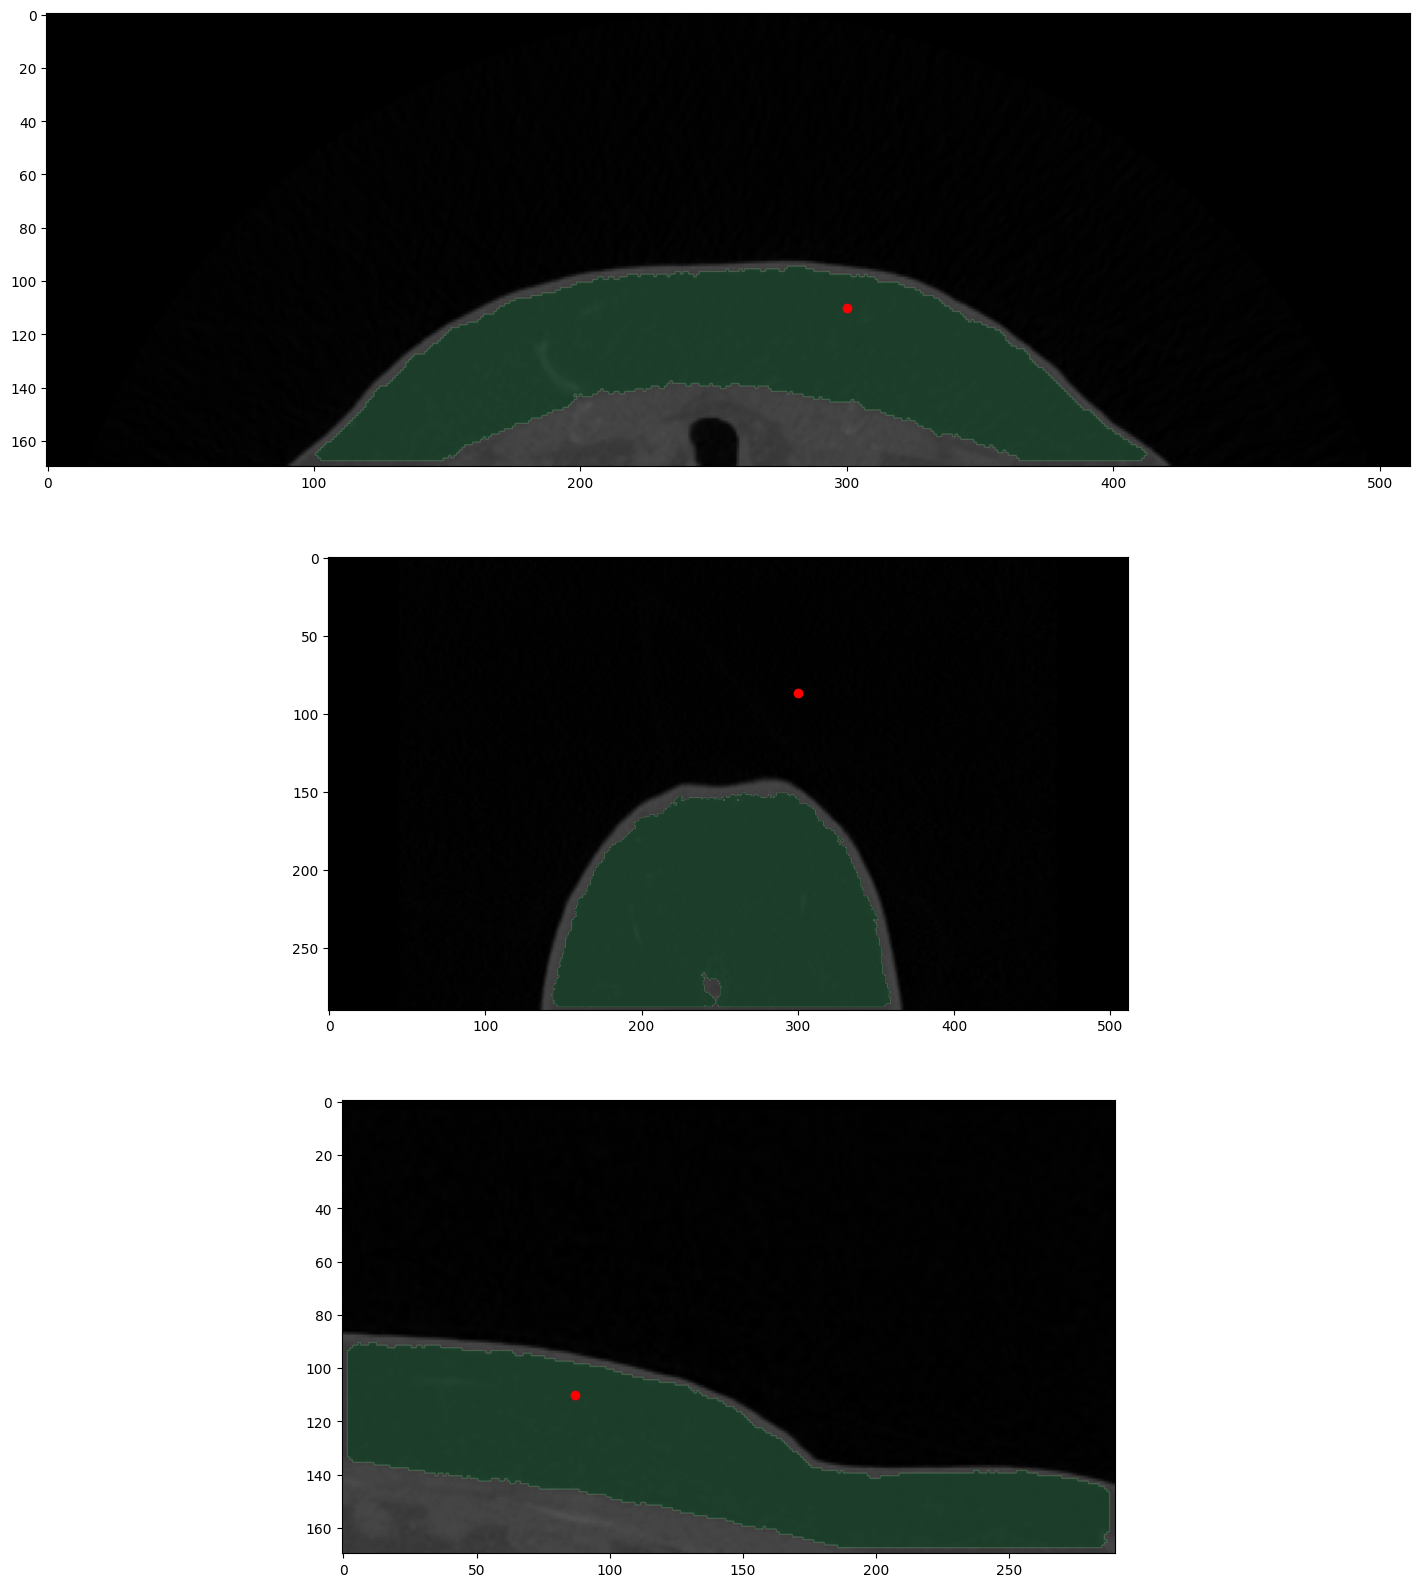

In [7]:
from functools import lru_cache
from scipy.ndimage import binary_erosion, binary_closing


def fill_small_holes(mask, max_size):
    # Find all connected components in the mask.
    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(1 - mask.astype(np.uint8))

    # Iterate over the connected components.
    for i in range(1, num_labels):
        # If the area of the connected component is less than the specified maximum size, fill it.
        if stats[i, cv2.CC_STAT_AREA] < max_size:
            mask[labels == i] = 1

    return mask


def remove_small_objects_windowed(mask, window_size=3, min_size=[1500, 600, 600]):
    k = window_size
    mask = mask.astype(bool)
    for element in range(3):
        slicing_array = [slice(None), slice(None), slice(None)]
        for i in range(0, mask.shape[element], k):
            for j in range(0, k, k // 2):
                slicing_array[element] = slice(i, i+k)
                # todo: replace remove_small_objects with a function that keeps the labels
                mask[*slicing_array] = remove_small_objects(mask[*slicing_array], min_size=min_size[element])

    return mask

def fat_region_growing(sitk_image, seed, lower=-150, upper=-50):
    return sitk.GetArrayFromImage(sitk.ConnectedThreshold(sitk_image, seedList=[seed[::-1]], lower=lower, upper=upper))

def get_larger_than_fat_area(sitk_image, seed):
    mask = fat_region_growing(sitk_image, seed)

    mask = gaussian_filter(mask, 0.1).astype(np.uint8)

    mask = binary_opening(mask, iterations=2).astype(np.uint8)
    mask = binary_erosion(mask, iterations=1)
    mask = remove_small_objects_windowed(mask, window_size=3, min_size=[2500, 1000, 1000])
    mask = binary_dilation(mask, iterations=7)
    mask = binary_erosion(mask, iterations=1)

    return mask.astype(bool)

def get_fat_and_organ_area(sitk_image, seed):
    mask = fat_region_growing(sitk_image, seed, lower=-160, upper=-40)
    mask = binary_fill_holes(mask)
    
    return mask.astype(bool)

def get_fat_area(sitk_image, seed):
    fat_dilated = get_larger_than_fat_area(sitk_image, seed)
    fat_and_organ = get_fat_and_organ_area(sitk_image, seed)
    mask = fat_and_organ * fat_dilated

    mask=binary_opening(mask, iterations=1).astype(np.uint8)
    mask = gaussian_filter(mask, 0.1).astype(np.uint8)
    mask = remove_small_objects_windowed(mask, window_size=3, min_size=[2500, 1000, 1000])
    mask = 1-remove_small_objects_windowed(1-mask, window_size=3, min_size=[2500, 1000, 1000])
    
    mask = binary_closing(mask, iterations=2)
    mask = binary_opening(mask, iterations=2)
    mask = gaussian_filter(mask, 0.1).astype(np.uint8)
    mask = binary_fill_holes(mask)
    
    return mask.astype(bool)

mask = get_fat_area(sitk_image, seed)

img = sitk.GetArrayFromImage(_sitk_image)[line_points["z_below_fat"]:line_points["z_above_fat"], :line_points["y_below_fat"], :]
show_slice(img, mask, (203, seed[1], seed[2]))

In [55]:
HP = {
    "slice_no": 203,  ## slice to visualize

    "vessel_size_threshold": 200,  # Minimum number of pixels for a region to be kept
    "vertical_vessel_size_threshold": 50,

    "frangi_scale_range": (1, 2),
    "frangi_scale_step": 0.2,
    "frangi_beta": 1,
    "frangi_gamma": 4,
}

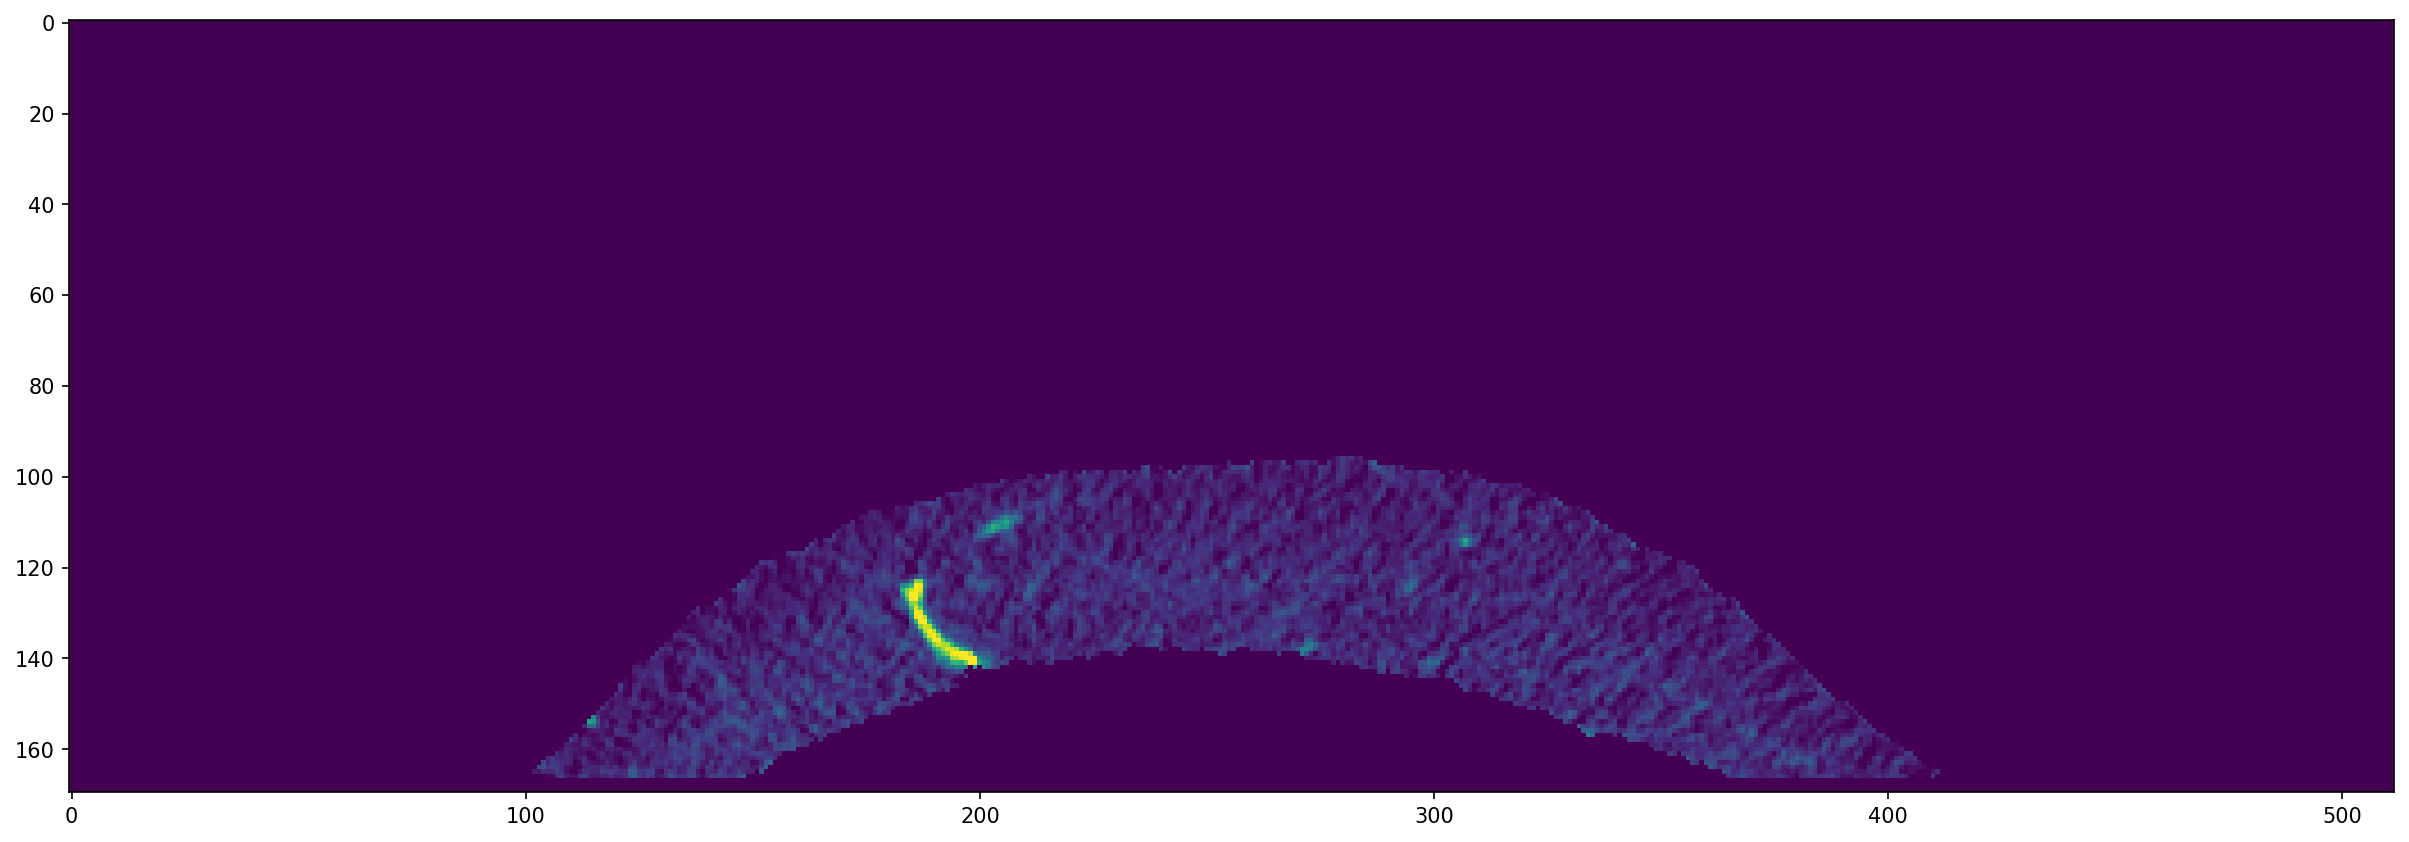

In [56]:
# img = sitk.GetArrayFromImage(sitk_image)
img_balanced = (img + 10000) * mask - 10000

max_value, min_value = np.percentile(img_balanced[mask.astype(bool)], [99.99, 5])
img_balanced = np.clip(img_balanced, min_value, max_value)

img_balanced = (img_balanced - min_value) / (max_value - min_value)

img_balanced = img_balanced[200:206]
HP["slice_no"] -= 200

plt.figure(figsize=(20, 15), dpi=150)
plt.imshow(img_balanced[HP["slice_no"]])

In [50]:
from skimage.filters import frangi

# Apply the Frangi filter with adjusted parameters
frangi_slice = frangi(
    img_balanced,
    scale_step=HP["frangi_scale_step"],  # More fine-grained scale steps
    beta=HP["frangi_beta"],  # More sensitive to line-like structures
    gamma=HP["frangi_gamma"],  # Less background suppression for more sensitivity
    black_ridges=False  # Assuming bright ridges on dark background
)

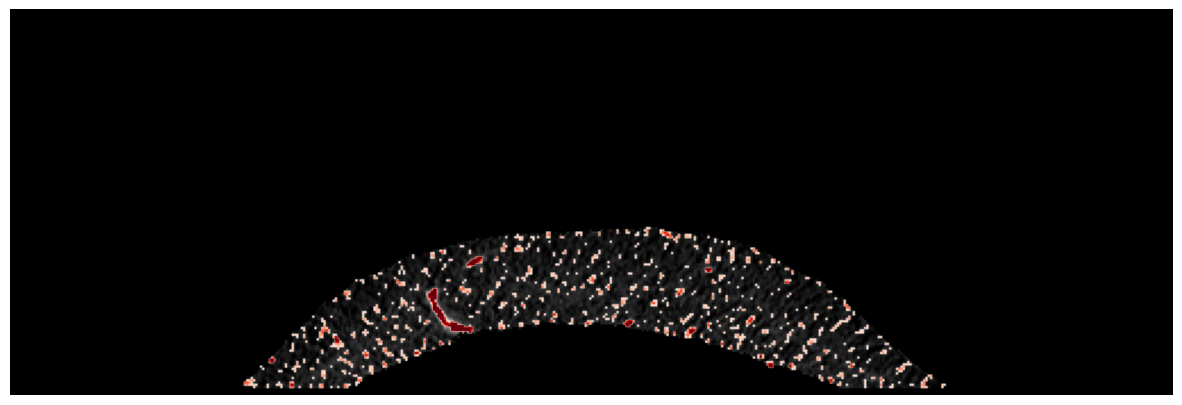

In [64]:
from scipy.ndimage import label

normlized_frangi = frangi_slice.copy()
normlized_frangi = np.clip(normlized_frangi,
                          *np.percentile(normlized_frangi[normlized_frangi > 0], [5,99.8]))
normlized_frangi /= np.max(normlized_frangi)
normlized_frangi[normlized_frangi < 0.1] = 0

plt.figure(figsize=(15, 10), dpi=100)
plt.imshow(img_balanced[HP['slice_no']], cmap="gray")
plt.imshow(normlized_frangi[HP['slice_no']], cmap='Reds', alpha=(normlized_frangi[HP['slice_no']] > 0).astype(float))
plt.axis('off')
plt.show()

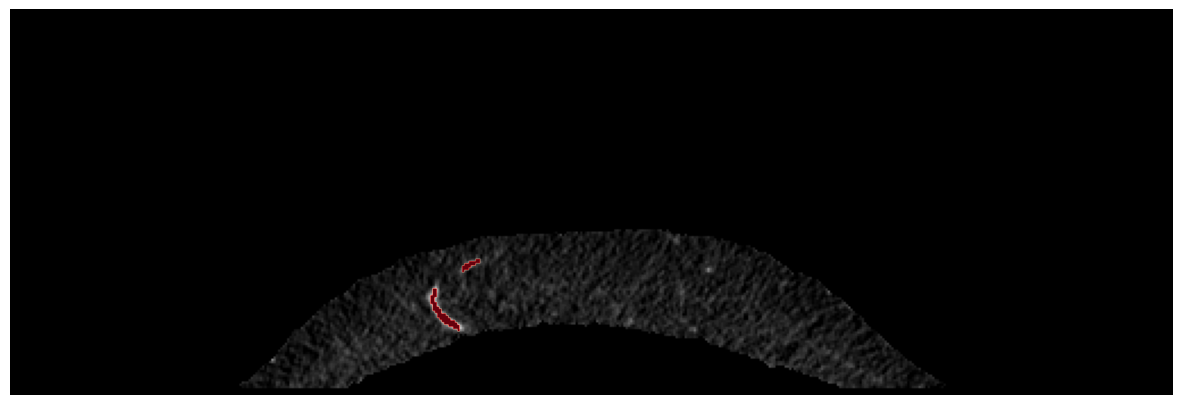

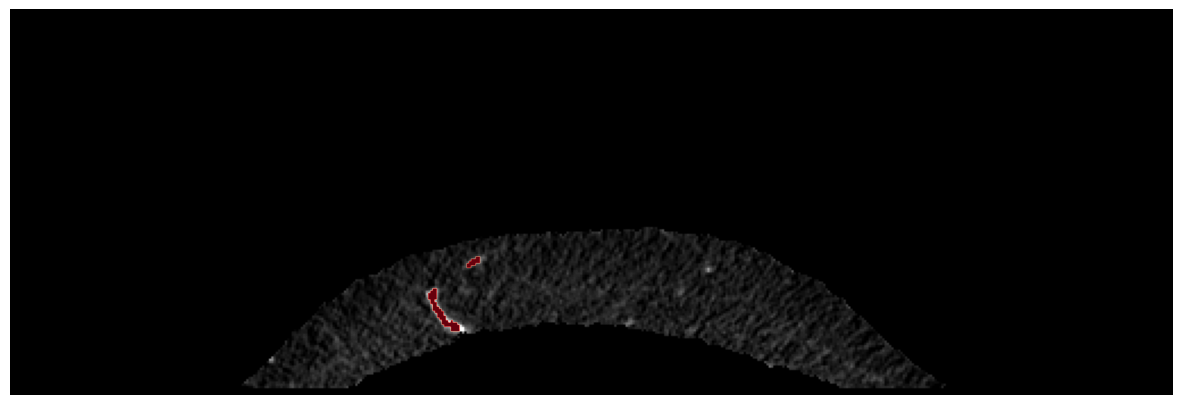

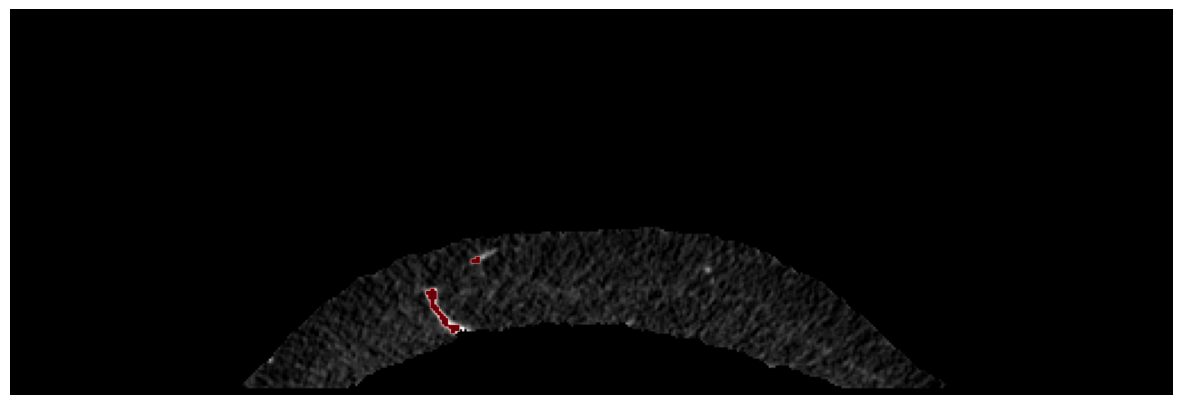

In [93]:
filtered_frangi = remove_small_objects_windowed(normlized_frangi, window_size=3, min_size=[50, 10, 20])


for i in np.arange(-1, 1+1, 1):
    plt.figure(figsize=(15, 10), dpi=100)
    temp = HP["slice_no"] + i
    plt.imshow(img_balanced[temp], cmap="gray")
    plt.imshow(filtered_frangi[temp], cmap='Reds', alpha=(filtered_frangi[temp] > 0).astype(float))
    plt.axis('off')
    plt.show()